# Gaussian EM under heavy and grouped gaps

**A02.3 · Sprint 6 · Subteam A · Rishank Goyal**

This notebook checks where Gaussian EM breaks as more predictors are missing or disappear together. It compares the scattered anchor with 70% independent missingness and 30% grouped missingness.

**Run this notebook.** Use a Python 3 Jupyter kernel with pandas and Matplotlib, then run all cells. The tables and figures use embedded extracts of the saved benchmark scores. They reproduce the analysis from those scores.

## Conditions and scoring

The three slices use the model-only arm, decay-corrected gas features, and ±5% measured noise. The anchor and grouped condition use nine matched generator–split pairs. The 70% scenario uses three pairs from generator seed 219. A separate comparison below uses those same three anchor pairs to show the heavy-missingness change.

The headline averages 13 numeric field skills within each pair, then gives each pair equal weight. The field-break calculation pools hidden-cell errors and tolerance counts within a condition. A field breaks if skill is below 0.10 or fewer than half of fills meet loose tolerance. A field is below the floor if pooled skill is negative.

In [1]:
%matplotlib inline
from io import StringIO
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

PAIR = ["generator_seed", "split_seed"]
FIELD = {
    "x": "x", "y": "y", "install_date": "Installation day", "model_id": "Model ID",
    "altitude": "Altitude", "measured_humid": "Humidity", "measured_salt": "Salt",
    "measured_overgrowth": "Overgrowth", "life": "Life", "random_placebo": "Placebo",
    "measured_gas_a": "Gas A", "measured_gas_b": "Gas B", "measured_gas_c": "Gas C",
    "total_gas": "Total gas", "leakage": "Leakage",
}
TEAL, NAVY, RUST, MUTE = "#087973", "#203e53", "#a3452a", "#647783"
plt.rcParams.update({
    "figure.dpi": 140, "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.labelcolor": NAVY,
    "axes.titlecolor": NAVY, "axes.axisbelow": True, "grid.alpha": 0.22,
})

In [2]:
CONDITIONS = ["30% scattered", "70% scattered", "30% grouped"]
NAMES = {"mixture": "Gaussian EM", "forest": "MissForest"}

In [3]:
# Archived score extract. Rows and columns are restricted to this analysis.
evidence = pd.read_csv(StringIO("""
condition,generator_seed,split_seed,attribute,n,error,floor_error,skill,tolerance
30% scattered,219,617,x,616,1.980097806982281,24.57792207792208,0.919435914854618,0.9155844155844156
30% scattered,219,617,y,606,9.15850124469651,29.12376237623763,0.6855316587746567,0.693069306930693
30% scattered,219,617,install_date,584,27.28576703991508,344.9332191780822,0.9208955081075332,0.7842465753424658
30% scattered,219,617,altitude,597,8.838004005242036,34.99832495812395,0.7474735143519913,0.6800670016750419
30% scattered,219,617,measured_humid,618,0.076290560685439,0.1741311408135003,0.5618787063070554,0.4401294498381877
30% scattered,219,617,measured_salt,575,0.1500873424597116,0.2162327144193579,0.3058990039377905,0.2626086956521739
30% scattered,219,617,measured_overgrowth,616,0.1035697483713957,0.2972701719120389,0.6515972399610896,0.3782467532467532
30% scattered,219,617,life,585,136.041760667481,274.5333408604432,0.5044617887171789,0.9811965811965812
30% scattered,219,617,measured_gas_a,578,310.8950257323459,1220.294894538314,0.7452295939909102,0.9463667820069204
30% scattered,219,617,measured_gas_b,624,233.9989653147818,1059.373948919212,0.7791158017869793,0.966346153846154
30% scattered,219,617,measured_gas_c,627,343.0527083693892,980.7439168797237,0.6502117398180502,0.9665071770334928
30% scattered,219,617,total_gas,589,275.6587637959782,1156.240811604538,0.7615905259273446,0.99660441426146
30% scattered,219,617,leakage,609,0.08482031141818951,0.09998389750598689,0.1516602819657978,0.632183908045977
30% scattered,219,631,x,570,2.29695124748228,25.88245614035088,0.9112545101969159,0.8982456140350877
30% scattered,219,631,y,587,9.08867121786167,25.73253833049404,0.6468023829933929,0.676320272572402
30% scattered,219,631,install_date,591,30.86621944871661,339.1006768189509,0.9089762375638184,0.7411167512690355
30% scattered,219,631,altitude,638,8.570086424582339,35.63949843260188,0.7595340338251592,0.6959247648902821
30% scattered,219,631,measured_humid,605,0.0750258474712569,0.1716513402382546,0.5629172054985419,0.4413223140495868
30% scattered,219,631,measured_salt,593,0.1433926356149744,0.2152094397975422,0.3337065709112449,0.2900505902192243
30% scattered,219,631,measured_overgrowth,554,0.1038645887033351,0.2931362468524875,0.6456781110539291,0.4296028880866426
30% scattered,219,631,life,582,139.5929601578407,279.8650680217949,0.5012133484734518,0.9810996563573884
30% scattered,219,631,measured_gas_a,594,321.2082404428822,1240.388415656093,0.7410422119486001,0.9528619528619529
30% scattered,219,631,measured_gas_b,596,250.2477004690227,1089.91145382662,0.770396301836799,0.9546979865771812
30% scattered,219,631,measured_gas_c,627,348.5893293520986,990.0155742840516,0.6478951054843884,0.9553429027113236
30% scattered,219,631,total_gas,587,268.8946794878867,1102.674572162893,0.7561432118993634,1
30% scattered,219,631,leakage,572,0.088250481826063,0.099290756221111,0.1111913617664711,0.6031468531468531
30% scattered,219,653,x,603,2.010463764318629,24.78441127694859,0.9188819237280608,0.913764510779436
30% scattered,219,653,y,577,6.900777060102097,21.24783362218371,0.6752244401566958,0.7105719237435009
30% scattered,219,653,install_date,599,27.06308515780012,354.0025041736227,0.9235511476932184,0.7813021702838063
30% scattered,219,653,altitude,593,6.695234580742896,29.52107925801012,0.7732049522232071,0.7048903878583473
30% scattered,219,653,measured_humid,617,0.0796270834789254,0.1827295049863342,0.5642352148610015,0.4457050243111831
30% scattered,219,653,measured_salt,585,0.1342257489442527,0.2090002966413376,0.3577724476889352,0.3094017094017094
30% scattered,219,653,measured_overgrowth,564,0.1037261631323146,0.3263559278686487,0.6821685948537076,0.4539007092198581
30% scattered,219,653,life,567,153.0220289578809,288.3500521776141,0.4693185321026943,0.9753086419753086
30% scattered,219,653,measured_gas_a,592,315.5681846144982,1209.022164938691,0.7389889170224597,0.9459459459459461
30% scattered,219,653,measured_gas_b,615,223.7749245700305,1061.448423208742,0.7891796533141362,0.9626016260162602
30% scattered,219,653,measured_gas_c,630,331.4722974427521,995.3032218080232,0.6669635040057296,0.9714285714285714
30% scattered,219,653,total_gas,606,263.6285678561844,1103.182309907934,0.7610290108094777,0.9983498349834984
30% scattered,219,653,leakage,612,0.0870918996908005,0.1015746857288105,0.142582632021889,0.6045751633986928
30% scattered,220,617,x,584,1.778086883498788,24.84931506849315,0.9284452356695636,0.9178082191780822
30% scattered,220,617,y,586,9.620521320821096,29.23720136518771,0.6709493087024361,0.6604095563139932
30% scattered,220,617,install_date,599,25.26122324340301,336.652754590985,0.9249635629029858,0.8013355592654424
30% scattered,220,617,altitude,609,8.944702245194875,34.8128078817734,0.7430628900842564,0.6683087027914614
30% scattered,220,617,measured_humid,578,0.077252919642714,0.1802419403603323,0.5713932091039793,0.4134948096885813
30% scattered,220,617,measured_salt,584,0.1444921486517222,0.207185875986769,0.302596530948135,0.2773972602739726
30% scattered,220,617,measured_overgrowth,629,0.0994036012856836,0.299570842978257,0.6681799860846326,0.4276629570747218
30% scattered,220,617,life,595,144.6010954916145,272.2572154989839,0.4688805759414145,0.9747899159663864
30% scattered,220,617,measured_gas_a,569,297.7269665163936,1227.054315280933,0.7573644762023193,0.9578207381370826
30% scattered,220,617,measured_gas_b,595,234.8636253968588,1066.815621340026,0.779846094583948,0.9663865546218487
30% scattered,220,617,measured_gas_c,605,322.8068225210419,945.145029625917,0.6584578954525032,0.968595041322314
30% scattered,220,617,total_gas,594,261.5374963695896,1068.509921895511,0.7552315696744973,1
30% scattered,220,617,leakage,600,0.0860166301056598,0.1011711155609459,0.1497906331393272,0.6333333333333333
30% scattered,220,631,x,594,2.356718899927387,24.72727272727273,0.9046915150764659,0.8838383838383839
30% scattered,220,631,y,599,9.02292295702981,25.90317195325543,0.6516672562992488,0.7111853088480802
30% scattered,220,631,install_date,600,32.10615788588259,339.5383333333334,0.9054417285651126,0.7
30% scattered,220,631,altitude,606,8.818350192977867,33.37458745874587,0.7357765034885246,0.7062706270627063
30% scattered,220,631,measured_humid,599,0.08079390789608989,0.1679047180772127,0.5188109731440902,0.4140233722871452
30% scattered,220,631,measured_salt,620,0.1454146625275082,0.2075831468319625,0.2994871464916147,0.2758064516129032
30% scattered,220,631,measured_overgrowth,580,0.1075697238486281,0.2919745681172522,0.6315784469096982,0.3913793103448276
30% scattered,220,631,life,618,133.6746797926701,284.7625250622748,0.5305748895033267,0.9789644012944984
30% scattered,220,631,measured_gas_a,595,404.4881875783218,1218.715951786745,0.6681029841405568,0.9008403361344538
30% scattered,220,631,measured_gas_b,632,232.3319657840137,1054.611049991877,0.7796989081559469,0.9620253164556962
30% scattered,220,631,measured_gas_c,591,374.2391442097533,922.154156229811,0.5941685653298854,0.9543147208121828
30% scattered,220,631,total_gas,583,263.5780039452454,1023.645765097593,0.7425105315410392,1
30% scattered,220,631,leakage,612,0.08369878811865861,0.0963134174457102,0.1309747869154598,0.6290849673202614
30% scattered,220,653,x,569,2.06928337632387,25.20035149384886,0.917886725634404,0.8945518453427065
30% scattered,220,653,y,626,6.689880449944075,21.19488817891374,0.6843634939957046,0.7252396166134185
30% scattered,220,653,install_date,573,28.79454971706859,344.5986038394415,0.9164403181085296,0.7574171029668412
30% scattered,220,653,altitude,600,6.692564138635475,29.49,0.7730564890255858,0.7083333333333334
30% scattered,220,653,measured_humid,584,0.08024528653569871,0.1728837013035385,0.5358423846166442,0.4178082191780822
30% scattered,220,653,measured_salt,608,0.1528066458814052,0.2142355952195552,0.2867354945157256,0.2927631578947368
30% scattered,220,653,measured_overgrowth,581,0.1085671053354087,0.3039601857515937,0.6428245855062962,0.3975903614457831
30% scattered,220,653,life,581,152.0334071424421,278.5106119664708,0.4541198769088735,0.9724612736660928
30% scattered,220,653,measured_gas_a,573,310.7078056734932,1264.247047217481,0.7542348970817536,0.9581151832460733
30% scattered,220,653,measured_gas_b,619,220.595343468563,1057.660710782905,0.7914308991346827,0.9612277867528272
30% scattered,220,653,measured_gas_c,607,317.8324449479543,930.8848419507208,0.6585695344636628,0.971993410214168
30% scattered,220,653,total_gas,622,257.4535663542162,1067.785898676155,0.7588902731592466,1
30% scattered,220,653,leakage,550,0.08791709643160441,0.1034524527837668,0.1501690480421363,0.5981818181818181
30% scattered,221,617,x,600,1.877882445109299,24.99833333333333,0.9248796941752396,0.9116666666666666
30% scattered,221,617,y,583,9.880926016970738,28.38078902229845,0.6518445625592928,0.6689536878216124
30% scattered,221,617,install_date,603,26.06855928064159,336.2504145936982,0.9224727817446976,0.8142620232172471
30% scattered,221,617,altitude,617,8.93900895155193,35.16045380875202,0.745765256609775,0.6888168557536467
30% scattered,221,617,measured_humid,610,0.0780635779359193,0.1713619112442683,0.5444519883730561,0.4327868852459016
30% scattered,221,617,measured_salt,597,0.1406949143266437,0.2053399690429569,0.3148196379770055,0.2864321608040201
30% scattered,221,617,measured_overgrowth,618,0.1041170906800552,0.2988041379067749,0.6515540534029045,0.4174757281553398
30% scattered,221,617,life,591,136.7331880454616,287.4906744309658,0.5243908752306508,0.976311336717428
30% scattered,221,617,measured_gas_a,620,303.302654736967,1273.119651315581,0.7617642187648674,0.9548387096774194
30% scattered,221,617,measured_gas_b,614,213.5704647444128,1092.573134712435,0.8045252459913135,0.972312703583062
30% scattered,221,617,measured_gas_c,574,332.0929470796308,950.4269253612144,0.6505855019275497,0.9790940766550522
30% scattered,221,617,total_gas,580,263.7438631146148,1064.668130437448,0.7522759857513078,0.9982758620689656
30% scattered,221,617,leakage,642,0.08336138476367511,0.0984679006585243,0.1534156389424494,0.6433021806853583
30% scattered,221,631,x,570,2.153243792507186,24.35789473684211,0.9115997578702754,0.8964912280701754
30% scattered,221,631,y,632,9.212400907303504,25.57594936708861,0.6398021916966212,0.7009493670886076
30% scattered,221,631,install_date,637,28.70450119970888,343.3971742543171,0.916410199757641,0.7488226059654631
30% scattered,221,631,altitude,613,9.40002953598434,33.95269168026101,0.7231433188123577,0.6867862969004894
30% scattered,221,631,measured_humid,589,0.0735794226338492,0.1745855587464715,0.5785480588305743,0.4142614601018676
30% scattered,221,631,measured_salt,608,0.1438068486503842,0.1988111276556108,0.2766659977931786,0.3026315789473684
30% scattered,221,631,measured_overgrowth,598,0.1061414366869591,0.2831033582396404,0.6250788498343671,0.3963210702341137
30% scattered,221,631,life,579,136.3320423427253,285.8070694871114,0.5229927566614188,0.9792746113989638
30% scattered,221,631,measured_gas_a,590,284.6199324763692,1273.565946889698,0.7765173188153563,0.9677966101694916
30% scattered,221,631,measured_gas_b,600,220.8516542380902,1065.032377058519,0.7926338588428141,0.9733333333333334
30% scattered,221,631,measured_gas_c,592,330.5285405922144,929.743034416504,0.6444947384847574,0.9712837837837838
30% scattered,221,631,total_gas,597,262.2463557371909,1135.697834776518,0.7690879143141137,1
30% scattered,221,631,leakage,601,0.0846382281915728,0.0978784504363145,0.1352720868150296,0.6306156405990017
30% scattered,221,653,x,584,1.961532477625739,24.11815068493151,0.9186698639024896,0.9246575342465754
30% scattered,221,653,y,619,7.139005893610086,21.12600969305331,0.662075044112209,0.7075928917609047
30% scattered,221,653,install_date,617,26.34369496162128,347.7811993517018,0.9242521015778642,0.8184764991896273
30% scattered,221,653,altitude,585,7.263020683211345,28.4017094017094,0.7442752272236752,0.6820512820512821
30% scattered,221,653,measured_humid,599,0.07437456595743849,0.168862766240481,0.5595561554906654,0.4457429048414023
30% scattered,221,653,measured_salt,590,0.1462877895935752,0.2149743264750568,0.319510417861229,0.2813559322033898
30% scattered,221,653,measured_overgrowth,586,0.1130582090480832,0.3110373992684573,0.636512492343397,0.3907849829351535
30% scattered,221,653,life,598,155.413454801033,319.255608067339,0.5132005487958335,0.9732441471571908
30% scattered,221,653,measured_gas_a,570,281.3928425880417,1254.040807848105,0.7756110958853857,0.968421052631579
30% scattered,221,653,measured_gas_b,559,223.7073483059957,1067.402903212183,0.7904190183174664,0.966010733452594
30% scattered,221,653,measured_gas_c,591,361.4375421215328,960.4717393202434,0.6236874784287419,0.9560067681895094
30% scattered,221,653,total_gas,602,268.7901431059107,1045.162597849416,0.7428245675275904,0.9983388704318936
30% scattered,221,653,leakage,587,0.08529300670770019,0.09836024631508219,0.1328508223283934,0.6337308347529813
70% scattered,219,617,x,1416,9.874559837475992,25.14265536723164,0.607258672831133,0.3672316384180791
70% scattered,219,617,y,1403,24.1678441272824,29.14540270848183,0.1707836611827246,0.0926585887384176
70% scattered,219,617,install_date,1410,136.5014102596988,349.8439716312056,0.6098220311665274,0.1730496453900709
70% scattered,219,617,altitude,1380,25.10823992241471,34.76594202898551,0.277792044251781,0.0884057971014492
70% scattered,219,617,measured_humid,1389,0.1300802149854451,0.1723377423097738,0.2452018156787248,0.2397408207343412
70% scattered,219,617,measured_salt,1369,0.2063744124686406,0.2165794163616766,0.0471189924900075,0.1475529583637691
70% scattered,219,617,measured_overgrowth,1434,0.217460934223354,0.2965867607475397,0.2667881274428805,0.1443514644351464
70% scattered,219,617,life,1385,213.9914981094034,274.0842164145471,0.2192491019411883,0.9061371841155236
70% scattered,219,617,measured_gas_a,1389,618.8799587650092,1235.672776956936,0.4991554638849363,0.7544996400287977
70% scattered,219,617,measured_gas_b,1414,580.0560870649523,1043.902854558523,0.4443390162868517,0.78995756718529
70% scattered,219,617,measured_gas_c,1419,552.3686003698631,961.0672315376506,0.4252549850377209,0.8054968287526427
70% scattered,219,617,total_gas,1368,486.1453960321669,1097.34664122418,0.556981014230989,0.9539473684210528
70% scattered,219,617,leakage,1386,0.0983555984092041,0.1005378013917213,0.0217052984281482,0.512987012987013
70% scattered,219,631,x,1405,9.910608195288004,25.33451957295373,0.6088100993291292,0.3637010676156583
70% scattered,219,631,y,1390,21.32839431332616,26.14028776978417,0.184079590050272,0.1661870503597122
70% scattered,219,631,install_date,1417,137.5354058152716,344.3719124911785,0.6006195603458377,0.1792519407198306
70% scattered,219,631,altitude,1397,23.45696358960225,35.05654974946314,0.3308821387945778,0.1424481030780243
70% scattered,219,631,measured_humid,1375,0.1237295552417917,0.1664697739072706,0.2567446189317625,0.2516363636363636
70% scattered,219,631,measured_salt,1424,0.1978722139174084,0.2100532382675437,0.0579901764457462,0.175561797752809
70% scattered,219,631,measured_overgrowth,1366,0.2076455717506511,0.2910833185561169,0.2866455804453119,0.1383601756954612
70% scattered,219,631,life,1409,206.5437260437796,278.8631019358828,0.2593364822741273,0.9176721078779276
70% scattered,219,631,measured_gas_a,1431,567.708074171504,1258.396478996938,0.5488639044635426,0.7624039133473096
70% scattered,219,631,measured_gas_b,1380,571.9861935599216,1068.046675152095,0.4644558080961506,0.7702898550724637
70% scattered,219,631,measured_gas_c,1390,539.6854870143228,974.586635816996,0.4462416503773373,0.8093525179856115
70% scattered,219,631,total_gas,1356,489.9478205465197,1098.851211634051,0.554127241832913,0.9454277286135692
70% scattered,219,631,leakage,1392,0.09860330275178281,0.1010426186386519,0.0241414555534483,0.5172413793103449
70% scattered,219,653,x,1420,10.12095204329307,25.15140845070422,0.5975989947787721,0.3711267605633803
70% scattered,219,653,y,1372,18.3909660358152,21.34548104956268,0.1384140749457604,0.1545189504373177
70% scattered,219,653,install_date,1408,139.8668820911467,350.2223011363636,0.6006339926460373,0.1740056818181818
70% scattered,219,653,altitude,1417,18.39535187546169,29.40508115737473,0.3744158780922741,0.1714890613973183
70% scattered,219,653,measured_humid,1443,0.1323316221858551,0.1762659147874239,0.2492500756856672,0.2501732501732501
70% scattered,219,653,measured_salt,1392,0.200183568275237,0.2090768797503681,0.0425360828311068,0.1724137931034483
70% scattered,219,653,measured_overgrowth,1396,0.2235516518658048,0.3135821584491507,0.2871034086524565,0.1418338108882521
70% scattered,219,653,life,1402,217.1725802857049,292.0006992764529,0.2562600677880713,0.9065620542082738
70% scattered,219,653,measured_gas_a,1419,604.7037189955755,1222.939025079898,0.5055324046462016,0.7484143763213531
70% scattered,219,653,measured_gas_b,1404,605.4633221644473,1056.213006925904,0.4267602101145855,0.7478632478632479
70% scattered,219,653,measured_gas_c,1444,565.3514210368267,970.4909850242472,0.4174583486494707,0.8033240997229917
70% scattered,219,653,total_gas,1408,498.5949244516214,1083.179224621284,0.5396930506805584,0.9438920454545454
70% scattered,219,653,leakage,1385,0.0998101753357291,0.1008556041450713,0.0103655995936368,0.5205776173285198
30% grouped,219,617,x,616,3.446175846640161,24.57792207792208,0.8597857119200569,0.8441558441558441
30% grouped,219,617,y,616,26.85056277003292,29.15422077922078,0.0790162778361669,0.06818181818181809
30% grouped,219,617,install_date,584,47.07932677205476,344.9332191780822,0.8635117635690849,0.7277397260273972
30% grouped,219,617,altitude,616,26.78342861268507,34.80681818181818,0.2305120085157406,0.06331168831168831
30% grouped,219,617,measured_humid,618,0.1131060376968322,0.1741311408135003,0.350454851622593,0.2718446601941747
30% grouped,219,617,measured_salt,618,0.2066417700828778,0.2130426401950365,0.0300450187169049,0.1601941747572815
30% grouped,219,617,measured_overgrowth,618,0.1757723404324178,0.3024526013078155,0.4188433504212819,0.2880258899676375
30% grouped,219,617,life,585,156.0633135445763,274.5333408604432,0.4315323848992541,0.9606837606837608
30% grouped,219,617,measured_gas_a,578,535.4530928905564,1220.294894538314,0.5612100851301689,0.842560553633218
30% grouped,219,617,measured_gas_b,578,376.3112336626947,1071.822197794574,0.6489051687518617,0.8892733564013841
30% grouped,219,617,measured_gas_c,578,503.7524094935058,940.3725586277438,0.4643054979947354,0.8806228373702422
30% grouped,219,617,total_gas,578,326.5946859202273,1029.391972705912,0.6827304908336091,0.9826989619377162
30% grouped,219,617,leakage,609,0.08725677081683381,0.09998389750598689,0.1272917640402153,0.6042692939244664
30% grouped,219,631,x,570,3.55198213177861,25.88245614035088,0.8627648739162335,0.856140350877193
30% grouped,219,631,y,570,24.69454111910146,25.84736842105263,0.0446013413501777,0.1157894736842105
30% grouped,219,631,install_date,591,44.52120726015256,339.1006768189509,0.8687079964634725,0.7461928934010152
30% grouped,219,631,altitude,570,25.19533397094106,36.17543859649123,0.3035237457111345,0.1052631578947368
30% grouped,219,631,measured_humid,605,0.1102402337727781,0.1716513402382546,0.3577665422258689,0.2975206611570248
30% grouped,219,631,measured_salt,605,0.2007626524133803,0.2090268688159058,0.0395366224894464,0.1619834710743801
30% grouped,219,631,measured_overgrowth,605,0.1843418798405026,0.3097747553152245,0.4049163894813905,0.2595041322314049
30% grouped,219,631,life,582,167.140742939873,279.8650680217949,0.4027809754132776,0.9484536082474226
30% grouped,219,631,measured_gas_a,594,535.2572189831429,1240.388415656093,0.5684761222959156,0.8434343434343434
30% grouped,219,631,measured_gas_b,594,373.1633750575472,1059.464002159312,0.6477809776481349,0.898989898989899
30% grouped,219,631,measured_gas_c,594,516.3591057175689,948.6661002885344,0.455699844697181,0.8585858585858586
30% grouped,219,631,total_gas,594,318.0415899816618,1106.726668304575,0.7126286019032336,0.9848484848484848
30% grouped,219,631,leakage,572,0.08772354724593689,0.099290756221111,0.1164983470305642,0.6101398601398601
30% grouped,219,653,x,603,3.952948959665099,24.78441127694859,0.8405066428452288,0.8325041459369817
30% grouped,219,653,y,603,20.43892698750191,21.09121061359867,0.0309267987526613,0.1077943615257048
30% grouped,219,653,install_date,599,52.67264657273517,354.0025041736227,0.8512082656146931,0.7245409015025042
30% grouped,219,653,altitude,603,20.94927598423492,28.91044776119403,0.2753735204214044,0.1194029850746268
30% grouped,219,653,measured_humid,617,0.1191027255307524,0.1827295049863342,0.3482020019719323,0.3095623987034036
30% grouped,219,653,measured_salt,617,0.2005772609300253,0.2095198943996332,0.0426815481901254,0.186385737439222
30% grouped,219,653,measured_overgrowth,617,0.1889693716653045,0.3194768492809504,0.4085037082010175,0.2658022690437601
30% grouped,219,653,life,567,179.8962505764538,288.3500521776141,0.3761185433542295,0.9382716049382716
30% grouped,219,653,measured_gas_a,592,548.7403878264123,1209.022164938691,0.5461287611263614,0.8344594594594594
30% grouped,219,653,measured_gas_b,592,386.4224697545255,1100.286106962521,0.6487981922980981,0.8885135135135135
30% grouped,219,653,measured_gas_c,592,534.465077680947,976.7176663847134,0.4527947061106706,0.8648648648648649
30% grouped,219,653,total_gas,592,331.1479957803787,1069.906107539588,0.6904887321917397,0.9695945945945946
30% grouped,219,653,leakage,612,0.088305244829131,0.1015746857288105,0.1306372823550443,0.5964052287581699
30% grouped,220,617,x,584,3.05656984812997,24.84931506849315,0.8769958109627961,0.8441780821917808
30% grouped,220,617,y,584,26.75267202454849,28.46746575342466,0.0602369646714996,0.0650684931506849
30% grouped,220,617,install_date,599,40.0229880989995,336.652754590985,0.8811149246420833,0.7429048414023373
30% grouped,220,617,altitude,584,26.78251916794328,34.375,0.2208721696598319,0.07191780821917799
30% grouped,220,617,measured_humid,578,0.1147635351768154,0.1802419403603323,0.363280627431191,0.2768166089965398
30% grouped,220,617,measured_salt,578,0.2047119917389048,0.2076044734261193,0.0139326558791316,0.1591695501730103
30% grouped,220,617,measured_overgrowth,578,0.1805412026683923,0.3089310307613209,0.4155938229206963,0.2543252595155709
30% grouped,220,617,life,595,154.6117295315717,272.2572154989839,0.4321115447823688,0.961344537815126
30% grouped,220,617,measured_gas_a,569,506.7523202365234,1227.054315280933,0.587017205411561,0.843585237258348
30% grouped,220,617,measured_gas_b,569,370.9927151975515,1029.519228715724,0.6396446954562012,0.9086115992970124
30% grouped,220,617,measured_gas_c,569,506.9293661404268,930.9593177515488,0.4554763495307596,0.859402460456942
30% grouped,220,617,total_gas,569,292.2146678941056,1100.797268993447,0.7345427027073728,0.984182776801406
30% grouped,220,617,leakage,600,0.0844368224781116,0.1011711155609459,0.1654058373286742,0.6116666666666667
30% grouped,220,631,x,594,4.332212985423348,24.72727272727273,0.8248002101483205,0.7946127946127947
30% grouped,220,631,y,594,25.58480692245044,26.96464646464646,0.051172172570671,0.1026936026936027
30% grouped,220,631,install_date,600,56.96405880791967,339.5383333333334,0.8322308463710441,0.6633333333333333
30% grouped,220,631,altitude,594,26.3901080382988,35.63804713804713,0.259496236253508,0.0959595959595959
30% grouped,220,631,measured_humid,599,0.1129604293575475,0.1679047180772127,0.3272349303156481,0.2754590984974958
30% grouped,220,631,measured_salt,599,0.2048877862515991,0.2118144377799472,0.0327015079847587,0.1636060100166945
30% grouped,220,631,measured_overgrowth,599,0.1875164025923455,0.2791581308153666,0.3282789147332137,0.1986644407345576
30% grouped,220,631,life,618,169.2591322736058,284.7625250622748,0.4056130376123386,0.9466019417475728
30% grouped,220,631,measured_gas_a,595,557.1705163455574,1218.715951786745,0.5428216759379441,0.8201680672268907
30% grouped,220,631,measured_gas_b,595,417.2751330897183,1066.065805926901,0.608584075420265,0.8739495798319328
30% grouped,220,631,measured_gas_c,595,542.3501299311044,961.0981677811128,0.4356974676341042,0.8420168067226891
30% grouped,220,631,total_gas,595,317.6164312628595,1044.883284127964,0.6960268806214707,0.976470588235294
30% grouped,220,631,leakage,612,0.0836442489619782,0.0963134174457102,0.131541054400581,0.619281045751634
30% grouped,220,653,x,569,3.925101498173359,25.20035149384886,0.8442441765492265,0.8172231985940246
30% grouped,220,653,y,569,20.36089162386878,21.68541300527241,0.0610789096376258,0.1089630931458699
30% grouped,220,653,install_date,573,51.41256420629034,344.5986038394415,0.8508044906930472,0.7137870855148342
30% grouped,220,653,altitude,569,20.94192956557195,28.47451669595782,0.2645378395994051,0.1124780316344463
30% grouped,220,653,measured_humid,584,0.1188105426409144,0.1728837013035385,0.3127718706559029,0.2808219178082192
30% grouped,220,653,measured_salt,584,0.2077421185121957,0.211453463215251,0.0175515910055221,0.1386986301369863
30% grouped,220,653,measured_overgrowth,584,0.1808035534844986,0.2961415049670782,0.3894690529630475,0.2517123287671233
30% grouped,220,653,life,581,163.8066112648924,278.5106119664708,0.4118478642220904,0.953528399311532
30% grouped,220,653,measured_gas_a,573,552.331913049657,1264.247047217481,0.5631139386362017,0.8167539267015707
30% grouped,220,653,measured_gas_b,573,396.9629696360246,1062.403362195423,0.626353808956597,0.8760907504363001
30% grouped,220,653,measured_gas_c,573,531.09925685675,962.5936356567216,0.4482622394501789,0.8551483420593369
30% grouped,220,653,total_gas,573,309.7554836543671,1036.172749880857,0.7010580680779492,0.9790575916230366
30% grouped,220,653,leakage,550,0.0878970005303511,0.1034524527837668,0.1503633005776019,0.6036363636363636
30% grouped,221,617,x,600,3.785378190577592,24.99833333333333,0.8485747773620538,0.8266666666666667
30% grouped,221,617,y,600,27.48495385903554,29.205,0.058895604895205,0.0566666666666666
30% grouped,221,617,install_date,603,49.78212557587738,336.2504145936982,0.8519492514647732,0.746268656716418
30% grouped,221,617,altitude,600,27.17039324263283,34.23,0.2062403376385383,0.0583333333333333
30% grouped,221,617,measured_humid,610,0.1123650834093139,0.1713619112442683,0.3442820368107192,0.3016393442622951
30% grouped,221,617,measured_salt,610,0.2041339261837659,0.208139502372448,0.0192446707281663,0.1622950819672131
30% grouped,221,617,measured_overgrowth,610,0.1772571350609749,0.2810705544948891,0.3693500360451379,0.2295081967213114
30% grouped,221,617,life,591,153.6220271547244,287.4906744309658,0.4656451815044415,0.957698815566836
30% grouped,221,617,measured_gas_a,620,534.9093125225373,1273.119651315581,0.5798436447275105,0.8387096774193549
30% grouped,221,617,measured_gas_b,620,403.7462711164106,1044.063371130062,0.6132933284696998,0.8790322580645161
30% grouped,221,617,measured_gas_c,620,537.3494231242241,963.6248251461188,0.4423665631043249,0.8741935483870967
30% grouped,221,617,total_gas,620,325.1354145858189,1038.580948417774,0.6869426354477748,0.9741935483870968
30% grouped,221,617,leakage,642,0.08433215960461631,0.0984679006585243,0.1435568440006572,0.6277258566978193
30% grouped,221,631,x,570,4.589270421564907,24.35789473684211,0.8115900215865747,0.7947368421052632
30% grouped,221,631,y,570,24.76465199660131,26.49298245614035,0.06523729302279691,0.1105263157894736
30% grouped,221,631,install_date,637,55.33003176669059,343.3971742543171,0.8388745280538807,0.717425431711146
30% grouped,221,631,altitude,570,25.3637540435422,34.43333333333333,0.2633953327141662,0.1140350877192982
30% grouped,221,631,measured_humid,589,0.1077000157969258,0.1745855587464715,0.3831103983043356,0.2716468590831918
30% grouped,221,631,measured_salt,589,0.1989225744261351,0.2047994662706613,0.0286958357438262,0.1680814940577249
30% grouped,221,631,measured_overgrowth,589,0.1726388972540505,0.2659766367008835,0.3509245797096093,0.2156196943972835
30% grouped,221,631,life,579,160.9103976477123,285.8070694871114,0.4369964398135064,0.9602763385146804
30% grouped,221,631,measured_gas_a,590,578.8836631242864,1273.565946889698,0.5454623574554299,0.8101694915254237
30% grouped,221,631,measured_gas_b,590,441.1233408519454,1089.130330194369,0.5949765343756228,0.8508474576271187
30% grouped,221,631,measured_gas_c,590,556.4408077669206,980.8454007333314,0.4326926472297303,0.8542372881355932
30% grouped,221,631,total_gas,590,345.3736578525873,1053.166006569682,0.6720615214523296,0.9661016949152542
30% grouped,221,631,leakage,601,0.0840399108458046,0.0978784504363145,0.1413849476449777,0.64891846921797
30% grouped,221,653,x,584,4.124183762297254,24.11815068493151,0.8290008294510759,0.827054794520548
30% grouped,221,653,y,584,20.25115117878246,21.6027397260274,0.0625656080842618,0.1301369863013698
30% grouped,221,653,install_date,617,52.28652548253338,347.7811993517018,0.8496568371723354,0.7568881685575365
30% grouped,221,653,altitude,584,21.11353448916177,28.00856164383562,0.2461756959301538,0.1164383561643835
30% grouped,221,653,measured_humid,599,0.1110877272873552,0.168862766240481,0.342141966754513,0.3222036727879799
30% grouped,221,653,measured_salt,599,0.2035975197824885,0.2056460737201965,0.009961551420112499,0.1619365609348914
30% grouped,221,653,measured_overgrowth,599,0.1852121972552136,0.2925047295632765,0.3668061452143208,0.2404006677796327
30% grouped,221,653,life,598,168.4026996988147,319.255608067339,0.4725145136266663,0.959866220735786
30% grouped,221,653,measured_gas_a,570,578.3135007896914,1254.040807848105,0.5388399666338932,0.8
30% grouped,221,653,measured_gas_b,570,432.2844147676046,1098.720813806138,0.6065566344646692,0.8578947368421053
30% grouped,221,653,measured_gas_c,570,556.9432386166287,974.7026407945272,0.4286018983567774,0.8526315789473684
30% grouped,221,653,total_gas,570,335.7960489121377,1064.603022289168,0.6845809734880419,0.9649122807017544
30% grouped,221,653,leakage,587,0.0870341183035015,0.09836024631508219,0.1151494474230905,0.6201022146507666
"""))

In [4]:
def pooled_fields(rows, keys):
    """Sum errors and tolerance counts before calculating each field score."""
    weighted = rows.assign(
        absolute_error=rows.error * rows.n,
        floor_absolute_error=rows.floor_error * rows.n,
        within_n=(rows.tolerance * rows.n).round().astype(int),
    )
    totals = weighted.groupby(keys)[["n", "absolute_error", "floor_absolute_error", "within_n"]].sum()
    totals["Skill"] = 1 - totals.absolute_error / totals.floor_absolute_error
    totals["Within loose"] = totals.within_n / totals.n
    totals["Breaks"] = totals.Skill.lt(0.10) | totals["Within loose"].lt(0.50)
    totals["Below floor"] = totals.Skill.lt(0)
    return totals

In [5]:
pair_scores = evidence.groupby(["condition", *PAIR]).skill.mean()
per_condition = pair_scores.groupby(level="condition").agg(["size", "mean"]).reindex(CONDITIONS)
pooled = pooled_fields(evidence, ["condition", "attribute"])
counts = pooled.groupby(level="condition")[["Breaks", "Below floor"]].sum().reindex(CONDITIONS)
report = per_condition.rename(columns={"size": "Pairs", "mean": "Mean numeric skill"}).join(counts)
assert report.Pairs.tolist() == [9, 3, 9]
assert report["Mean numeric skill"].round(3).tolist() == [0.641, 0.345, 0.435]
assert report.Breaks.tolist() == [3, 8, 5]
assert report["Below floor"].tolist() == [0, 0, 0]

## Mean scores and field breaks

In [6]:
display(report.style.format({"Mean numeric skill": "{:.3f}"}))
heavy = pair_scores.xs("70% scattered", level="condition")
matched = pd.DataFrame({
    "30% scattered": pair_scores.xs("30% scattered", level="condition").reindex(heavy.index),
    "70% scattered": heavy,
})
assert matched.notna().all().all() and len(matched) == 3
display(matched.style.format(precision=3))
display(matched.mean().to_frame("Mean on three common pairs").style.format(precision=3))

broken = pooled.loc[pooled.Breaks].reset_index().assign(
    Field=lambda d: d.attribute.map(FIELD)
).set_index(["condition", "Field"])
display(broken.loc[CONDITIONS, ["Skill", "Within loose"]].style.format({
    "Skill": "{:.3f}", "Within loose": "{:.1%}",
}))

,Pairs,Mean numeric skill,Breaks,Below floor
condition,,,,
30% scattered,9,0.641,3,0
70% scattered,3,0.345,8,0
30% grouped,9,0.435,5,0


,Mean on three common pairs
30% scattered,0.645
70% scattered,0.345


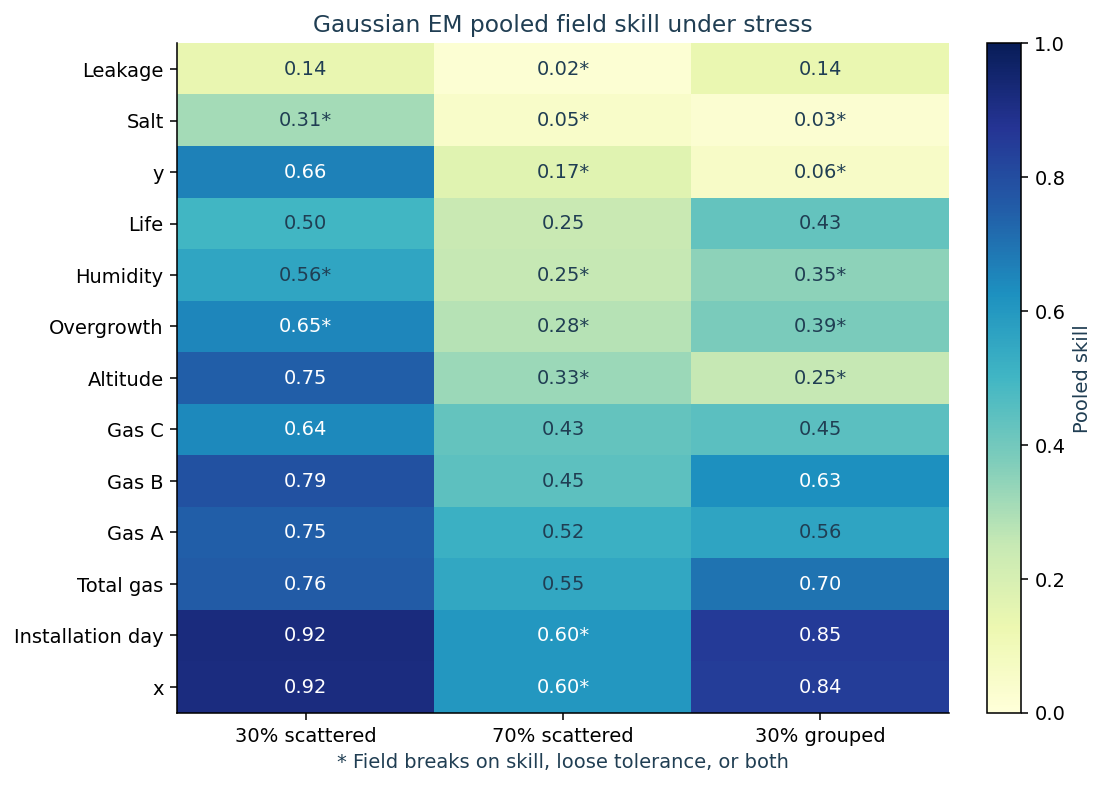

In [7]:
heat = pooled.Skill.unstack("condition")[CONDITIONS].rename(index=FIELD)
heat = heat.sort_values("70% scattered")
flags = pooled.Breaks.unstack("condition")[CONDITIONS].rename(index=FIELD).reindex(heat.index)
fig, ax = plt.subplots(figsize=(7.8, 5.5), layout="constrained")
image = ax.imshow(heat.to_numpy(), cmap="YlGnBu", vmin=0, vmax=1, aspect="auto")
for i, field in enumerate(heat.index):
    for j, condition in enumerate(CONDITIONS):
        value = heat.loc[field, condition]
        mark = "*" if flags.loc[field, condition] else ""
        ax.text(j, i, f"{value:.2f}{mark}", ha="center", va="center",
                color="white" if value >= 0.60 else NAVY)
ax.set(xticks=range(len(CONDITIONS)), xticklabels=CONDITIONS,
       yticks=range(len(heat)), yticklabels=heat.index,
       title="Gaussian EM pooled field skill under stress",
       xlabel="* Field breaks on skill, loose tolerance, or both")
fig.colorbar(image, ax=ax, label="Pooled skill")
plt.show()

## Interpretation

Mean skill drops to 0.345 at 70% scattered gaps and 0.435 under grouped gaps. In the grouped case the break count rises from three to five. y and altitude join the three environmental fields, and all 13 fields remain at or above the median floor.

At 70% scattered gaps eight fields break, while pooled skill stays nonnegative on every field. This distinction matters because a method can beat the median and still fall short of a field’s loose error tolerance. The grouped comparison is a synthetic stress case for jointly missing inputs.

## Sources and reproducibility

Paths are relative to the original Subteam A run archive. Hash prefixes identify the archived files. The embedded extracts allow the calculations above to run in a fresh notebook session. Use the repository’s setup and benchmark instructions to reproduce the source runs with the Team 19 data.

| Archived source | Evidence used | SHA-256 prefix |
| --- | --- | --- |
| final/tables/cells.csv | Gaussian EM anchor and 70% independent scenario | 9d8119486d0cbae0 |
| anchor-stress/tables/cells.csv | Gaussian EM 30% grouped scenario on matched generator–split pairs | f4b3c14586d8bf47 |

[Sections 7, 8, and 8A of the capstone report](https://github.com/alienblack/SAPN_endtoend/blob/6ae6621/docs/Final_Report.pdf) · [Source code and reproduction guide](https://github.com/alienblack/SAPN_endtoend)